# Coding Assignment 10: Least Squares and LASSO

---
## What You'll Learn
- Solve overdetermined systems with `np.linalg.lstsq`
- Translate ridge and LASSO formulas into short NumPy functions
- Use coordinate descent to see why LASSO can set coefficients exactly to zero
- **Milestone:** fit a sparse linear output head to transformer hidden states

## Estimated Time: 2–3 hours
---


## Start here: how to work through this notebook

You do not need to remember an earlier programming course. Work one small step
at a time. The mathematics is the goal; the programming examples are here to
help you express it.

1. Save your own copy of the notebook. A **cell** is one block of text or code.
   Click a code cell and press **Shift+Enter** to run it. Run cells from the top
   down: later cells use names created by earlier cells.
2. Run the setup cell first. `import numpy as np` makes NumPy's array tools
   available under the short name `np`.
3. Read the explanation and run the small practice example before attempting
   the corresponding task. Practice cells are supplied; you may experiment
   with them, but restore them before the final run.
4. Edit only the requested task or response. `#` begins a comment. `pass` is a
   placeholder that does nothing; a function ending at `pass` returns `None`
   (no result). Replace it with your calculation and a `return` statement.
5. Running a cell containing `def` stores the function; it does not call it.
   After editing the definition, run that cell again, then run its check cell.
   A successful `assert` may print nothing. A skipped check is not a pass:
   if a result is still `None`, the task is unfinished.
6. If a check fails, stop there. Read the last line of the error, print the
   relevant array's `.shape`, and fix this task before running cells that need it.
   Errors below an unfinished task are expected and are not separate failures.
7. Save, restart the kernel/runtime (the Python session), and run everything
   from the beginning once your work is complete. This catches accidental use
   of a value left over from an earlier attempt.

**Reading code:** `=` stores a value; `==` compares values; `@` multiplies
matrices; `*` multiplies entries or scales an array; `**2` squares entries.
Python indices start at **0**: mathematical entry $a_{1,1}$ is `A[0, 0]`.
`A.shape` is `(number_of_rows, number_of_columns)`, `A.ndim` counts dimensions,
and `A.T` transposes a matrix. An ordinary vector has shape `(n,)`.

**If you get stuck:** record the function name, the smallest input that fails,
its shape, the expected mathematical result, and the last line of the error.
Include these when asking for help. You do not need to rewrite the whole cell.

**Plan your time:** if Python is new to you, allow extra time beyond the
headline estimate and work in several short sessions. Start with setup and
the practice example; then finish one task at a time.

More worked examples and an error-message checklist: [Python and NumPy help](`mt_utils.py` / `mini_transformer.py` in this folder).


### Files, dependencies, and what you are expected to edit

Save this notebook and download the supplied helper
`mt_utils.py` (same folder as this notebook)
using GitHub's **Download raw file** button. Put it beside the notebook; in
Colab, upload it through the Files panel before setup. This is a read-only
instructor helper for making reproducible toy data. Do not edit or submit it.
If Python cannot find it, check the filename and working folder first.

The notebook uses NumPy and Matplotlib. Colab normally provides both. Locally,
install missing packages in the notebook's environment with
`%pip install numpy matplotlib`, then restart the kernel. Run this installation
command only if setup reports a missing package.

Four cells are marked **YOUR TASK**. Together they are worth 20 points:

| Task | Points |
|---|---:|
| Ridge formula | 5 |
| Soft-threshold function | 5 |
| One LASSO coordinate update | 5 |
| Sparse output-head wrapper | 5 |

Each task first states the mathematics, the input/output shapes, and a small
check. Replace only the marked placeholder; keep function names and arguments
unchanged. Supplied demonstrations and the coordinate-descent loop are there
for you to run and trace, not rewrite.

Save and submit the completed notebook using the assignment's the course portal link.
The optional cumulative copy in `mini_transformer.py` is explained near the
end; it is not an additional submission. Never paste model code into the
instructor helper.


In [1]:
%%writefile mt_utils.py
import numpy as np

def set_seed(seed):
    np.random.seed(seed)

def make_embedding_matrix(num_tokens, embedding_dim):
    rng = np.random.default_rng(412)
    return rng.standard_normal((num_tokens, embedding_dim))


Overwriting mt_utils.py


In [2]:
# Supplied practice: run this unchanged, then trace the result by hand.
import numpy as np

def double_and_total(values):
    values = np.asarray(values, dtype=float)  # turn a list into a numerical array
    doubled = 2 * values                     # one intermediate calculation
    total = np.sum(doubled)                   # add all entries
    return doubled, total                    # send two results back to the caller

practice_vector, practice_total = double_and_total([1, -2, 3])
print(practice_vector)        # [ 2. -4.  6.]
print(practice_vector.shape)  # (3,)
print(practice_total)         # 4.0
assert practice_total == 4.0


[ 2. -4.  6.]
(3,)
4.0


## Setup


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sys; sys.path.insert(0, ".")
import mt_utils
np.set_printoptions(precision=4, suppress=True)
print("Setup complete.")


Setup complete.


---
## Part 1: The small NumPy patterns we need

This assignment does **not** require generators, `yield`, or power iteration.
The iterative LASSO loop later is supplied. Your job is to translate a few
linear-algebra formulas into NumPy and explain what their outputs mean.

`np.linalg.lstsq(A, b, rcond=None)` returns four values. We need the first:
the coefficient vector that minimizes `||A @ x - b||`. The commas below
**unpack** the four returned values into four names. For an `(m,n)` matrix,
the coefficient vector has shape `(n,)` and the prediction `A @ x` has shape
`(m,)`.


In [4]:
# Supplied practice: run this unchanged and verify the shapes.
A_small = np.array([[1., 0.],
                    [1., 1.],
                    [1., 2.]])
b_small = np.array([1., 2., 2.])

x_small, residuals_small, rank_small, singular_values_small = np.linalg.lstsq(
    A_small, b_small, rcond=None
)
prediction_small = A_small @ x_small

print("coefficients:", x_small)
print("coefficient shape:", x_small.shape)
print("prediction shape:", prediction_small.shape)
print("residual length:", np.linalg.norm(prediction_small - b_small))
assert x_small.shape == (2,)
assert prediction_small.shape == (3,)


coefficients: [1.1667 0.5   ]
coefficient shape: (2,)
prediction shape: (3,)
residual length: 0.4082482904638629


---
## Part 2: Linear Algebra — Least Squares and Regularization

### 2.1 Overdetermined Systems and `np.linalg.lstsq`

When $A \in \mathbb{R}^{m \times n}$ has $m > n$ (more equations than unknowns),
$Ax = b$ need not have an exact solution. The least-squares solution minimizes $\|Ax - b\|^2$:

$$x^* = (A^\top A)^{-1} A^\top b \quad \text{(when } A \text{ has full column rank)}$$

`np.linalg.lstsq` handles rank-deficient cases automatically via SVD.


In [5]:
# 2.1 Overdetermined system
rng = np.random.default_rng(412)
m, n = 50, 4
A_ols = rng.standard_normal((m, n))
x_true = np.array([1., -2., 0.5, 3.])
b_ols = A_ols @ x_true + 0.2 * rng.standard_normal(m)

# Method 1: normal equations
x_ne = np.linalg.solve(A_ols.T @ A_ols, A_ols.T @ b_ols)

# Method 2: lstsq (safer — uses SVD, handles rank-deficient A)
x_lstsq, residuals, rank, sv = np.linalg.lstsq(A_ols, b_ols, rcond=None)

print(f"Normal equations: {x_ne.round(4)}")
print(f"lstsq:            {x_lstsq.round(4)}")
print(f"True x:           {x_true}")
print(f"Rank of A: {rank},  Condition number: {sv[0]/sv[-1]:.2f}")
print(f"Residual ||Ax - b||: {np.linalg.norm(A_ols @ x_lstsq - b_ols):.4f}")


Normal equations: [ 1.0372 -2.0333  0.481   2.9787]
lstsq:            [ 1.0372 -2.0333  0.481   2.9787]
True x:           [ 1.  -2.   0.5  3. ]
Rank of A: 4,  Condition number: 1.49
Residual ||Ax - b||: 1.3067


### 2.2 Ridge Regression (L2 Regularization) — YOUR TASK 1 (5 points)

Ridge balances two goals:
$$\min_x \|Ax-b\|^2 + \lambda\|x\|^2.$$

For `A` with shape `(m,n)`, the coefficient vector `x` has shape `(n,)`.
The normal equation is
$$(A^\top A + \lambda I_n)x=A^\top b.$$

**Translate the equation in three pieces:**
1. `A.T @ A` is `(n,n)`;
2. `lam * np.eye(n)` is the same shape;
3. `np.linalg.solve(left, right)` solves `left @ x = right`.

Replace the marked placeholder with one return statement. Do not form a matrix
inverse. The check uses a tiny system whose answer is easy to inspect. As
`lam` increases, the coefficient norm should generally shrink, while the
training residual may grow.

**Why ridge also works with duplicate features.** Two identical columns do
not let ordinary least squares determine their coefficients separately.
For a positive penalty, however, every nonzero vector $z$ satisfies
$$z^T(A^TA+\lambda I)z=\|Az\|_2^2+\lambda\|z\|_2^2>0.$$
Thus $A^TA+\lambda I$ has no nonzero null vector and is invertible, even
when $A$ has dependent columns or more columns than rows. Add the penalty
**before** solving; do not first solve or invert the unregularized $A^TA$.

For a hand check, take
$$A=\begin{bmatrix}1&1\\1&1\end{bmatrix},\quad
b=\begin{bmatrix}4\\2\end{bmatrix},\quad\lambda=2.$$
The ridge equation becomes
$$\begin{bmatrix}4&2\\2&4\end{bmatrix}x=\begin{bmatrix}6\\6\end{bmatrix},$$
so $x=(1,1)^T$ and the prediction is $(2,2)^T$.
Without the penalty, every $x_1+x_2=3$ is a best fit. Ridge instead accepts
some additional fitting error to reduce coefficient size.

**Input contract:** `b` has shape `(m,)`. For `lam > 0`, columns may be
dependent. When `lam == 0`, assume full column rank; handling a singular
unpenalized system is not part of this task. No extra branching is needed.


In [6]:
def ridge(A, b, lam):
    n = A.shape[1]
    left = A.T @ A + lam * np.eye(n)
    right = A.T @ b
    return np.linalg.solve(left, right)

ridge_check = ridge(np.eye(2), np.array([2., -4.]), lam=1.0)
if ridge_check is None:
    print("Task 1 not complete: replace return None.")
else:
    print("ridge check:", ridge_check)
    assert ridge_check.shape == (2,)
    assert np.allclose(ridge_check, [1., -2.])

# Supplied second check: identical columns, but a positive ridge penalty.
A_duplicate = np.array([[1., 1.], [1., 1.]])
b_duplicate = np.array([4., 2.])
duplicate_check = ridge(A_duplicate, b_duplicate, lam=2.0)
if duplicate_check is None:
    print("Task 1 duplicate-feature check not complete: replace return None.")
else:
    assert duplicate_check.shape == (2,), "Return one coefficient per column."
    assert np.allclose(duplicate_check, [1., 1.]), (
        "Add lam * I to A.T @ A before solving, even for dependent columns."
    )
    print("duplicate-feature ridge coefficients:", duplicate_check)
    print("prediction:", A_duplicate @ duplicate_check)  # expected [2., 2.]

lambdas = [0., 0.01, 0.1, 1., 10., 100.]
print(f"{'lambda':>8}  {'||x||':>8}  {'||Ax-b||':>10}")
for lam in lambdas:
    x_r = ridge(A_ols, b_ols, lam)
    if x_r is None:
        break
    res = np.linalg.norm(A_ols @ x_r - b_ols)
    print(f"{lam:>8.3f}  {np.linalg.norm(x_r):>8.4f}  {res:>10.4f}")


ridge check: [ 1. -2.]
duplicate-feature ridge coefficients: [1. 1.]
prediction: [2. 2.]
  lambda     ||x||    ||Ax-b||
   0.000    3.7834      1.3067
   0.010    3.7826      1.3068
   0.100    3.7750      1.3080
   1.000    3.7011      1.4184
  10.000    3.1102      4.7355
 100.000    1.2697     17.5610


### 2.3 LASSO (L1 Regularization) via Coordinate Descent

LASSO uses an absolute-value penalty:
$$\min_x \frac{1}{2m}\|Ax-b\|^2+\lambda\|x\|_1.$$

Here `m` is the number of data rows. Coordinate descent updates one
coefficient at a time. For column $a_j$, first form the **partial residual**
$r_j=b-Ax+x_j a_j$: the current prediction error after temporarily removing
coefficient $x_j$. Then
$$
x_j\leftarrow
\operatorname{soft\_threshold}\!\left(
\frac{a_j^\top r_j}{\|a_j\|^2},
\frac{\lambda m}{\|a_j\|^2}
\right),
$$
where
$$
\operatorname{soft\_threshold}(z,\tau)
=\operatorname{sign}(z)\max(|z|-\tau,0).
$$

The threshold explains the sparsity directly: if $|z|\leq\tau$, the updated
coefficient is exactly zero. The ridge and LASSO values of `lam` are not on
the same scale because their objectives above use different normalizations.


### YOUR TASKS 2 and 3: two small pieces, then a supplied loop

**Task 2 (5 points): soft threshold.** Implement the displayed formula using
`np.sign`, `np.abs`, and `np.maximum`. NumPy applies these functions
entry by entry, so the same line must work for a scalar or an array.

**Task 3 (5 points): one coordinate update.** Inputs `a_j` and `r_j` both
have shape `(m,)`. Compute:

1. `col_norm_sq = a_j @ a_j`;
2. `rho = a_j @ r_j`;
3. return the soft-threshold formula above.

Assume `a_j` is not the zero vector and `lam >= 0`. The full
coordinate-descent loop below is supplied. Trace how it constructs `r_j`
and calls your one-coordinate helper; do not rewrite the loop.

**Keep the sign.** A negative coefficient is allowed: it means this feature
contributes in the opposite direction. The penalty shrinks a coefficient
toward zero; it does not require coefficients to be nonnegative.

For a second hand check, take $a_j=(1,0)^T$, $r_j=(-2,7)^T$,
$m=2$, and $\lambda=0.25$. Then $a_j^T r_j=-2$,
$\|a_j\|^2=1$, and the threshold is $0.5$. The update is
$-\max(2-0.5,0)=-1.5$. Before running the checks, explain why the
positive and negative examples have equal magnitudes and opposite signs.


In [7]:
def soft_threshold(z, tau):
    return np.sign(z) * np.maximum(np.abs(z) - tau, 0)

def lasso_coordinate_update(a_j, r_j, lam, m):
    col_norm_sq = a_j @ a_j
    rho = a_j @ r_j
    return soft_threshold(rho / col_norm_sq, (lam * m) / col_norm_sq)

# SUPPLIED: coordinate descent assembles residuals and calls your helper.
def lasso_cd(A, b, lam, max_iter=500, tol=1e-6):
    m, n = A.shape
    x = np.zeros(n)
    for _ in range(max_iter):
        x_old = x.copy()
        for j in range(n):
            r_j = b - A @ x + x[j] * A[:, j]
            x[j] = lasso_coordinate_update(A[:, j], r_j, lam, m)
        if np.linalg.norm(x - x_old) < tol:
            break
    return x

threshold_check = soft_threshold(np.array([2., 0.2, -3.]), 0.5)
if threshold_check is None:
    print("Task 2 not complete: replace return None.")
else:
    print("soft-threshold check:", threshold_check)
    assert np.allclose(threshold_check, [1.5, 0., -2.5])

update_check = lasso_coordinate_update(
    np.array([1., 0.]), np.array([2., 7.]), lam=0.25, m=2
)
if update_check is None:
    print("Task 3 not complete: replace return None.")
else:
    print("coordinate-update check:", update_check)
    assert np.isclose(update_check, 1.5)

negative_update_check = lasso_coordinate_update(
    np.array([1., 0.]), np.array([-2., 7.]), lam=0.25, m=2
)
if negative_update_check is None:
    print("Task 3 negative check not complete: replace return None.")
else:
    print("negative coordinate-update check:", negative_update_check)
    assert np.isclose(negative_update_check, -1.5), (
        "Keep the sign of a_j @ r_j: shrink toward zero, not past zero."
    )

# Supplied application: recover a sparse signal after Tasks 2 and 3 work.
x_sparse_true = np.array([0., 3., 0., -2., 0., 1., 0., 0.])
m_lasso = 100
A_lasso = rng.standard_normal((m_lasso, 8))
b_lasso = A_lasso @ x_sparse_true + 0.1 * rng.standard_normal(m_lasso)

if threshold_check is not None and update_check is not None:
    x_lasso = lasso_cd(A_lasso, b_lasso, lam=0.05)
    x_ridge_ = ridge(A_lasso, b_lasso, lam=0.1)
    print("True     x:", x_sparse_true)
    print("LASSO    x:", x_lasso.round(4))
    print("Ridge    x:", x_ridge_.round(4))
    print(f"LASSO nonzeros: {(np.abs(x_lasso) > 1e-4).sum()}/8")
    print(f"Ridge nonzeros: {(np.abs(x_ridge_) > 1e-4).sum()}/8")


soft-threshold check: [ 1.5  0.  -2.5]
coordinate-update check: 1.5
negative coordinate-update check: -1.5
True     x: [ 0.  3.  0. -2.  0.  1.  0.  0.]
LASSO    x: [-0.      2.94    0.     -1.9479  0.      0.9354 -0.      0.    ]
Ridge    x: [-0.0098  2.9932 -0.0021 -2.0031  0.0015  0.9971 -0.006   0.0073]
LASSO nonzeros: 3/8
Ridge nonzeros: 8/8


---
## Part 3: DS/AI Application — Comparing OLS, Ridge, LASSO on Synthetic Data

We'll use a synthetic "word features" dataset where only a few features actually
predict the target — a setting where LASSO shines.


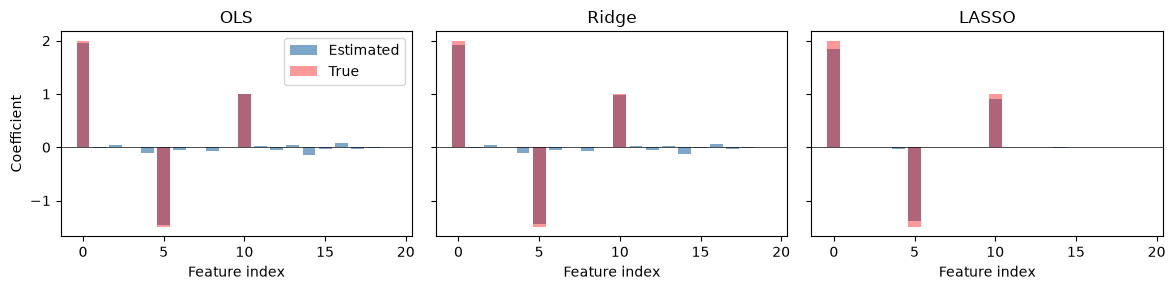

LASSO nonzeros: 5


In [8]:
# Supplied comparison after Tasks 1–3 are complete.
rng2 = np.random.default_rng(99)
n_obs, n_feat = 80, 20
x_true_sparse = np.zeros(n_feat)
x_true_sparse[[0, 5, 10]] = [2., -1.5, 1.]

X_data = rng2.standard_normal((n_obs, n_feat))
y_data = X_data @ x_true_sparse + rng2.standard_normal(n_obs) * 0.5

x_ols_ = np.linalg.lstsq(X_data, y_data, rcond=None)[0]
x_rdg_ = ridge(X_data, y_data, lam=1.0)
x_las_ = lasso_cd(X_data, y_data, lam=0.1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, x_est, name in zip(
    axes, [x_ols_, x_rdg_, x_las_], ["OLS", "Ridge", "LASSO"]
):
    ax.bar(range(n_feat), x_est, color="steelblue", alpha=0.7, label="Estimated")
    ax.bar(range(n_feat), x_true_sparse, color="red", alpha=0.4, label="True")
    ax.set_title(name)
    ax.set_xlabel("Feature index")
    ax.axhline(0, color="k", lw=0.5)
axes[0].set_ylabel("Coefficient")
axes[0].legend()
plt.tight_layout()
plt.savefig("hw10_lasso_comparison.png", dpi=100)
plt.show()
print("LASSO nonzeros:", (np.abs(x_las_) > 0.01).sum())


---
## Part 4: Mini-Transformer Milestone — A Sparse Linear Output Head

A transformer produces one hidden-state row for each token. A **linear output
head** multiplies those features by a weight vector to predict one numeric
target:
$$\widehat y=Hw.$$

The toy target below is a scalar score attached to each token. It is useful for
studying the linear algebra, but it is **not** a complete next-token classifier;
a classifier would normally produce one score per possible class.


In [9]:
# Milestone setup — produce hidden states from attention + layernorm
mt_utils.set_seed(412)
E = mt_utils.make_embedding_matrix(6, 8)
rng3 = np.random.default_rng(412)
d = 8
W_Q = rng3.standard_normal((d,d)) * 0.1
W_K = rng3.standard_normal((d,d)) * 0.1
W_V = rng3.standard_normal((d,d)) * 0.1

def softmax(X):
    X_s = X - X.max(axis=1, keepdims=True)
    e = np.exp(X_s); return e / e.sum(axis=1, keepdims=True)

def attention_head(X, WQ, WK, WV):
    Q,K,V = X@WQ, X@WK, X@WV
    return softmax(Q @ K.T / np.sqrt(d)) @ V

def layer_norm_batch(X, eps=1e-5):
    mu = X.mean(axis=1, keepdims=True)
    sig = X.std(axis=1, keepdims=True)
    return (X - mu) / (sig + eps)

# Use all 6 tokens as training examples
X_all = E    # (6, 8)
H = layer_norm_batch(X_all + attention_head(X_all, W_Q, W_K, W_V))
print("Hidden states H:", H.shape)

# Toy task: predict token index (0-5) from hidden state
y_labels = np.arange(6, dtype=float)

# Fit linear head W_out via lstsq
W_out, _, _, _ = np.linalg.lstsq(H, y_labels, rcond=None)
y_pred = H @ W_out
print("Predictions:", y_pred.round(3))
print("True labels:", y_labels)
print("MSE:", np.mean((y_pred - y_labels)**2).round(6))


Hidden states H: (6, 8)
Predictions: [0. 1. 2. 3. 4. 5.]
True labels: [0. 1. 2. 3. 4. 5.]
MSE: 0.0


### YOUR TASK 4 (5 points): package the sparse head

Write the short wrapper `fit_sparse_head(H, y, lam)`. It must call
`lasso_cd(H, y, lam=lam)` and return the resulting coefficient vector.

- `H` has shape `(number of items, number of features)`;
- `y` has one numeric target per item;
- the returned vector has one weight per feature;
- `H @ weights` produces one prediction per item.

This task checks that you can connect the solver to model features without
reimplementing coordinate descent. Then compare the number of nonzero weights
and the mean squared error for OLS and LASSO. Sparsity is a tradeoff, not an
automatic improvement in training error.


In [10]:
def fit_sparse_head(H, y, lam):
    return lasso_cd(H, y, lam=lam)

W_out_lasso = fit_sparse_head(H, y_labels, lam=0.1)

if W_out_lasso is None:
    print("Task 4 not complete: replace return None.")
else:
    y_pred_lasso = H @ W_out_lasso
    print("LASSO predictions:", y_pred_lasso.round(3))
    print("OLS   nonzeros:", (np.abs(W_out) > 1e-4).sum())
    print("LASSO nonzeros:", (np.abs(W_out_lasso) > 1e-4).sum())
    print("OLS   MSE:", np.mean((y_pred - y_labels) ** 2).round(6))
    print("LASSO MSE:", np.mean((y_pred_lasso - y_labels) ** 2).round(6))


LASSO predictions: [0.259 0.375 1.968 2.945 4.003 4.524]
OLS   nonzeros: 8
LASSO nonzeros: 6
OLS   MSE: 0.0
LASSO MSE: 0.114879


### Optional project checkpoint: save the same sparse head in your model file

The notebook is the graded artifact. This checkpoint keeps your cumulative
`mini_transformer.py` honest without requiring an extra the course portal file.

1. Download **this assignment's** `student/mini_transformer.py` and keep it
   beside the notebook. It contains completed earlier checkpoints.
2. Search for **THIS WEEK**. The full coordinate-descent loop is supplied, but
   `soft_threshold`, `lasso_coordinate_update`, and `fit_sparse_head` have
   the same short placeholders as the notebook.
3. After the notebook versions pass, transfer **your own three function bodies**
   into the model file. Do not paste the entire notebook or edit earlier model
   components.
4. Save the file and run the reload/check cell below. A match confirms that the
   saved model component reproduces the notebook calculation.

The instructor helper `mt_utils.py` remains read-only. If the model file is
absent, the check reports **NOT RUN**, not a pass. That does not affect the
notebook-only grading path.


In [11]:
import importlib
try:
    import mini_transformer as mt
except ModuleNotFoundError as error:
    if error.name != "mini_transformer":
        raise
    print("Project checkpoint NOT RUN: place mini_transformer.py beside the notebook.")
    print("This optional portfolio check is separate from the graded notebook.")
else:
    mt = importlib.reload(mt)
    mt.check_milestone()
    if not hasattr(mt, "fit_sparse_head"):
        print("Optional project sync skipped: this mini_transformer.py snapshot")
        print("has no fit_sparse_head (cumulative helper is from a later week).")
    else:
        project_weights = mt.fit_sparse_head(H, y_labels, lam=0.1)
        assert W_out_lasso is not None, "Finish Task 4 in the notebook first."
        assert np.allclose(project_weights, W_out_lasso)
        print("Saved project component agrees with the notebook.")


HW11 project checks passed. Continue with the notebook experiment.
Optional project sync skipped: this mini_transformer.py snapshot
has no fit_sparse_head (cumulative helper is from a later week).


### Submission checklist
- [ ] Task 1: `ridge` passes both its identity and duplicate-feature checks
- [ ] Task 2: `soft_threshold` works for positive, small, and negative entries
- [ ] Task 3: `lasso_coordinate_update` passes its check
- [ ] Task 4: `fit_sparse_head` returns one weight per feature
- [ ] The OLS/Ridge/LASSO comparison plot is generated as `hw10_lasso_comparison.png`
- [ ] I restarted the runtime and ran every notebook cell from top to bottom
- [ ] I submitted exactly one completed `.ipynb` notebook
